# Exploration of distress events

How should a "distress event" be defined? The risk monitor currently flags a borrower-quarter when the
borrower's value return is at or below the pooled 1st percentile (about -19%), among borrowers with at
least $1M of prior fair value (`distress_event_study.py`, `docs/13_distress_event_study.md`).

This notebook steps back from that choice:

1. **One quarter**: what the cross-section of markdowns looks like at a single date.
2. **The life of a borrower**: what markdowns look like over the whole time we observe a borrower.
3. **Definitions**: a cutoff on the quarterly return, per-quarter and fixed variants, a market-relative
   version, a slow-bleed (multi-quarter drawdown) version, a price-level version, a continuous score,
   and fundamentals-based flags (non-accrual, PIK toggle). Each is compared on how many events it
   finds, when, who, and whether flagged borrowers go on to non-accrual.

The borrower-quarter table `b` is built by `distress_event_study.borrower_quarter_panel` (all BDCs
pooled). `val_ret` is the change in fair value net of new cost, over prior fair value plus new cost.
Nothing here writes to `outputs/`.

## Measuring the value of a loan

Everything below comes from each BDC's quarterly schedule of investments, one row per loan per BDC. Three reported amounts (fair value, cost and par) feed two derived measures (`val_ret` and price).

### 1. Fair value (FV)

FV is the BDC's own estimate of what the loan it holds would sell for today. Most of these loans never trade, so the number is a model or valuation-agent mark approved by the BDC's board, not a market price. FV is for the amount the BDC has actually funded, roughly *price × principal outstanding*. It is not for the full commitment, and it is not tied to cost.

What moves FV:

- **Credit changes.** The borrower's earnings, leverage or liquidity improve or deteriorate, or the loan is restructured. This is the source of large markdowns.
- **Market changes.** Spreads on comparable loans widen or tighten, or rates move (less for floating-rate loans), and the loan gets closer to maturity.
- **Mechanical changes.** The dollar FV changes with the amount of principal held, with no change in the lender's view of the loan:
  - a **draw** (the borrower takes money from a committed revolver or delayed-draw loan) raises principal, so FV rises;
  - **PIK interest** (paid by adding to principal instead of in cash) raises principal, so FV rises;
  - a **paydown** (the borrower repays principal) lowers principal, so FV falls.

  So yes, PIK, draws and paydowns all change FV, which is why FV changes cannot be read as markdowns without adjusting for them.
- **Valuation practice.** Marks can lag real events, and two lenders can mark the same loan differently.

### 2. Cost

Cost is the lender's amortized cost, its carrying basis on the books. It starts at what the BDC paid or funded, including any discount or premium to par. The discount or premium is then *amortized*: spread over the life of the loan, so the cost of a loan bought at 98 drifts up toward 100 at maturity. FV minus cost is the lender's unrealized gain or loss.

Cost and par differ when:
- the loan was bought or issued at a discount or premium;
- a revolver or delayed-draw loan is partly drawn: par is the whole commitment, cost is only the drawn amount;
- the BDC wrote the cost down after a loss;
- par is reported in a local currency (GBP, EUR, AUD) while FV and cost are in USD, a data issue the code screens for.

Draws and paydowns move cost, and PIK moves cost when it is capitalized. That is why cost is used to adjust FV in `val_ret`.

### 3. Par

Par is the principal amount, the face value the borrower owes under the loan terms. For a fully drawn loan it is the principal outstanding. It rises with PIK and falls with paydowns. For a partly drawn revolver or delayed-draw loan, the schedule can report the whole commitment as par, which can overstate the amount actually lent.

### 4. Value return (`val_ret`)

`val_ret` is the markdown measure behind stress events: the change in a loan's value after removing the effect of money moving in and out.

```
val_ret = (FV_t - FV_t-1 - (Cost_t - Cost_t-1)) / (FV_t-1 + max(Cost_t - Cost_t-1, 0))
```

- Subtracting the change in cost removes draws, paydowns and PIK, which move FV and cost together. What is left is repricing.
- The denominator is last quarter's FV plus any new money.
- It does not use par.
- Numerators and denominators are summed across all BDCs holding the borrower, giving one return per borrower-quarter.
- It exists only when the loan appears in consecutive quarters and last quarter's FV is positive. Stress events also require at least $1M of prior FV.
- `val_ret_w` caps the return at ±100% for averaging.

A caveat: PIK cancels only if a BDC raises cost when it capitalizes PIK. We have not checked this BDC by BDC. A BDC that leaves cost unchanged would show PIK as a gain.

### 5. Price (FV ÷ par) and why only some rows are priced

Price is FV divided by par, how far the loan is marked from face value (1.00 = par). It is computed only on rows where par is what was actually lent:

- **Funded:** FV and cost are positive and cost is at least 5% of par.
- **Cost at least 80% of par:** this rules out rows where cost sits far below par.

A partly drawn revolver reports $10M par and $1M cost. Its FV is on the $1M drawn, so FV ÷ par would show a 90% markdown that does not exist. A cost write-down or a deep-discount purchase has the same problem: FV ÷ par then mixes a loss with how the loan was acquired. These rows stay in the loan history (they are the same loan), but are left out of prices. Prices above 1.2 in the lender-dispersion code, or above 1.5 in the borrower panel, are dropped as currency errors.

Price is used for the price-level definition in section 3 (`price_80`) and for comparing lenders' marks on the same loan. `val_ret` is used for everything else.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src" / "1_data_processing"))
from paths import FINAL_DIR, add_code_dirs_to_path  # noqa: E402
add_code_dirs_to_path()

from monitor_panel import build_monitor_panel  # noqa: E402
import distress_event_study as D  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

## 0. Build the borrower-quarter table

This is the slow cell (a few minutes). Everything below uses only `b`.

In [2]:
panel, rows = build_monitor_panel(FINAL_DIR / "FINAL_DATASET.csv")
b = D.borrower_quarter_panel(panel, rows)
print(f"{len(b):,} borrower-quarters, {b['borrower'].nunique():,} borrowers, "
      f"{b['cal_q'].min()} to {b['cal_q'].max()}")

103,420 borrower-quarters, 14,649 borrowers, 2023Q1 to 2026Q2


In [3]:
MIN_FV = D.MIN_FV_PREV
b = b.sort_values(["borrower", "qsort"]).reset_index(drop=True)
b["eligible"] = b["val_ret"].notna() & (b["fv_prev"] >= MIN_FV)
e = b[b["eligible"]].copy()                       # the borrower-quarters every definition is judged on
POOLED = D.pooled_cutoff(b)
print(f"{len(e):,} eligible borrower-quarters; pooled 1% cutoff {POOLED:.1%}")

81,123 eligible borrower-quarters; pooled 1% cutoff -19.3%


## 1. Markdowns in a single quarter

Pick one quarter and look at the cross-section of `val_ret`. Set `QUARTER` to any `cal_q`; the default is
the latest quarter with at least 150 eligible borrowers (the most recent quarters can be thin).

2026Q2: 7,653 borrowers, median -0.01%, 53% marked down, 69 at or below the pooled cutoff


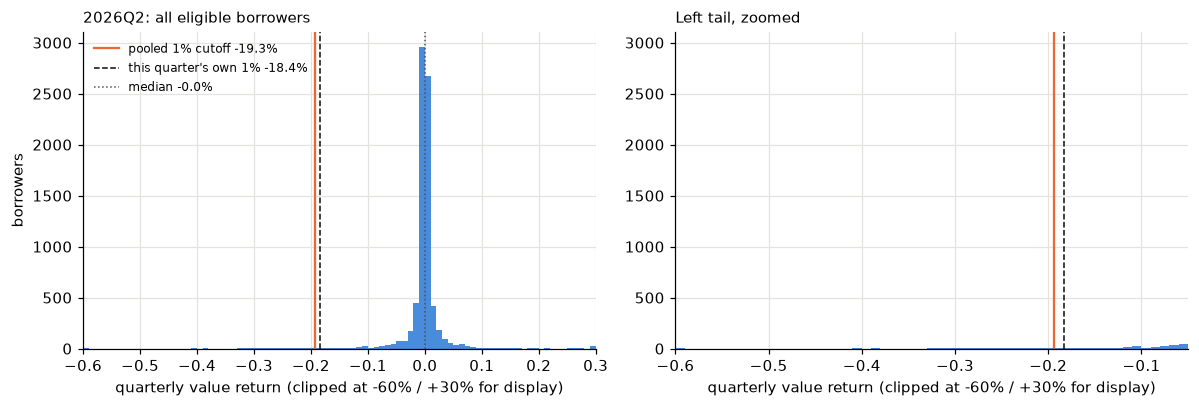

In [4]:
counts = e.groupby("cal_q").size()
QUARTER = counts[counts >= 150].index.max()
q = e[e["cal_q"] == QUARTER]["val_ret"]
q_p1 = q.quantile(0.01)
print(f"{QUARTER}: {len(q):,} borrowers, median {q.median():.2%}, "
      f"{(q < 0).mean():.0%} marked down, {(q <= POOLED).sum()} at or below the pooled cutoff")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(-0.6, 0.3, 91)
for ax, xlim, title in [(axes[0], (-0.6, 0.3), f"{QUARTER}: all eligible borrowers"),
                        (axes[1], (-0.6, -0.05), "Left tail, zoomed")]:
    ax.hist(q.clip(-0.6, 0.3), bins=bins, color=BLUE, alpha=0.85)
    ax.axvline(POOLED, color=ORANGE, lw=1.5, label=f"pooled 1% cutoff {POOLED:.1%}")
    ax.axvline(q_p1, color=INK, lw=1, ls="--", label=f"this quarter's own 1% {q_p1:.1%}")
    ax.axvline(q.median(), color=MUTED, lw=1, ls=":", label=f"median {q.median():.1%}")
    ax.set_xlim(*xlim)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("quarterly value return (clipped at -60% / +30% for display)")
axes[0].legend(fontsize=8, frameon=False)
axes[0].set_ylabel("borrowers")
plt.tight_layout()

In [5]:
# The same cross-section for every quarter: how much does the shape move?
qt = e.groupby("cal_q")["val_ret"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75]).drop(columns=["std", "min", "max"])
qt["share_down"] = e.groupby("cal_q")["val_ret"].apply(lambda s: (s < 0).mean())
qt["below_pooled"] = e.groupby("cal_q")["val_ret"].apply(lambda s: (s <= POOLED).sum())
qt.round(3)

,count,mean,1%,5%,25%,50%,75%,share_down,below_pooled
cal_q,,,,,,,,,
2023Q2,4393.0,0.001,-0.168,-0.040,-0.002,0.000,0.007,0.402,38
2023Q3,4716.0,-0.001,-0.175,-0.040,-0.002,0.000,0.008,0.402,39
2023Q4,4995.0,0.003,-0.136,-0.028,-0.001,0.001,0.008,0.384,41
2024Q1,5445.0,-0.002,-0.177,-0.037,-0.002,0.000,0.006,0.416,51
2024Q2,5741.0,-0.001,-0.212,-0.038,-0.003,0.000,0.004,0.466,68
2024Q3,6016.0,-0.001,-0.173,-0.035,-0.003,-0.000,0.003,0.518,57
2024Q4,6149.0,-0.005,-0.173,-0.069,-0.003,0.000,0.004,0.472,54
2025Q1,6650.0,-0.004,-0.178,-0.042,-0.006,-0.001,0.001,0.601,59
2025Q2,6883.0,0.002,-0.191,-0.030,-0.002,0.000,0.005,0.478,68


**What to look at.** A thick mass near zero with a long left tail means a fixed cutoff is meaningful.
If the median and the 1% move together across quarters (the table above), a fixed cutoff flags
market-wide repricings as borrower distress.

## 2. Markdowns across the life of a borrower

Two different things can be called a markdown history: (a) the pool of all quarterly returns a borrower
had, and (b) the path of its cumulative value, where several modest markdowns compound. For (b) we chain
`val_ret_w` (return capped at ±100%) through consecutive quarters; a gap in coverage starts a new
segment so a missing quarter is never treated as flat.

In [6]:
def life_paths(e_all: pd.DataFrame) -> pd.DataFrame:
    """Per borrower-quarter: chained value index within consecutive-quarter segments, its running peak,
    and the drawdown from that peak. Uses every borrower-quarter with a return (not only >= $1M)."""
    d = e_all[e_all["val_ret"].notna()].sort_values(["borrower", "qsort"]).copy()
    new_seg = (d["borrower"] != d["borrower"].shift()) | (d["qsort"].diff() != 1)
    d["seg"] = new_seg.cumsum()
    d["index"] = d.groupby("seg")["val_ret_w"].transform(lambda s: (1 + s).cumprod())
    d["peak"] = d.groupby("seg")["index"].cummax().clip(lower=1.0)      # start of segment = 1.0
    d["drawdown"] = d["index"] / d["peak"] - 1
    return d

paths = life_paths(b[b["fv_prev"] >= MIN_FV])
life = paths.groupby("borrower").agg(
    quarters=("val_ret", "size"),
    worst_quarter=("val_ret", "min"),
    max_drawdown=("drawdown", "min"),
    cum_return=("index", "last"),
    quarters_down=("val_ret", lambda s: (s < 0).sum()),
    quarters_down_5=("val_ret", lambda s: (s <= -0.05).sum()),
)
life["cum_return"] -= 1
print(f"{len(life):,} borrowers with at least one eligible return; median {life['quarters'].median():.0f} quarters")
life.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95]).round(3)

12,078 borrowers with at least one eligible return; median 6 quarters


,quarters,worst_quarter,max_drawdown,cum_return,quarters_down,quarters_down_5
count,12078.000,12078.000,12078.000,12078.000,12078.000,12078.000
mean,6.717,-0.036,-0.052,-0.020,3.441,0.318
std,4.119,0.093,0.124,0.132,2.761,0.908
min,1.000,-0.969,-0.989,-0.989,0.000,0.000
1%,1.000,-0.532,-0.696,-0.651,0.000,0.000
5%,1.000,-0.178,-0.278,-0.203,0.000,0.000
25%,3.000,-0.027,-0.036,-0.011,1.000,0.000
50%,6.000,-0.008,-0.011,0.000,3.000,0.000
75%,11.000,-0.001,-0.002,0.010,5.000,0.000
95%,13.000,0.002,0.000,0.062,9.000,2.000


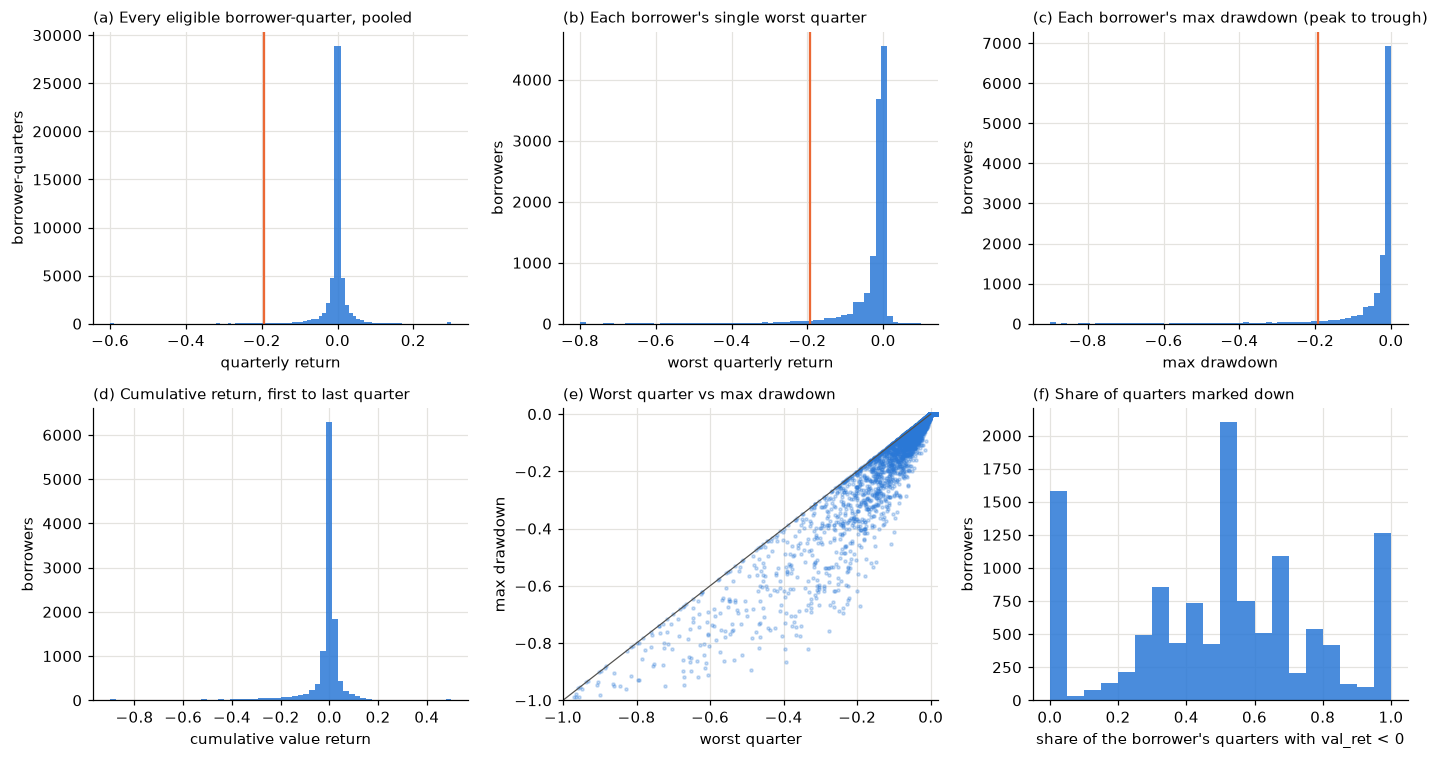

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
ax = axes[0, 0]
ax.hist(e["val_ret"].clip(-0.6, 0.3), bins=np.linspace(-0.6, 0.3, 91), color=BLUE, alpha=0.85)
ax.axvline(POOLED, color=ORANGE, lw=1.5)
ax.set_title("(a) Every eligible borrower-quarter, pooled", loc="left", fontsize=10)
ax.set_xlabel("quarterly return"); ax.set_ylabel("borrower-quarters")

ax = axes[0, 1]
ax.hist(life["worst_quarter"].clip(-0.8, 0.1), bins=60, color=BLUE, alpha=0.85)
ax.axvline(POOLED, color=ORANGE, lw=1.5)
ax.set_title("(b) Each borrower's single worst quarter", loc="left", fontsize=10)
ax.set_xlabel("worst quarterly return"); ax.set_ylabel("borrowers")

ax = axes[0, 2]
ax.hist(life["max_drawdown"].clip(-0.9, 0), bins=60, color=BLUE, alpha=0.85)
ax.axvline(POOLED, color=ORANGE, lw=1.5)
ax.set_title("(c) Each borrower's max drawdown (peak to trough)", loc="left", fontsize=10)
ax.set_xlabel("max drawdown"); ax.set_ylabel("borrowers")

ax = axes[1, 0]
ax.hist(life["cum_return"].clip(-0.9, 0.5), bins=60, color=BLUE, alpha=0.85)
ax.set_title("(d) Cumulative return, first to last quarter", loc="left", fontsize=10)
ax.set_xlabel("cumulative value return"); ax.set_ylabel("borrowers")

ax = axes[1, 1]
ax.scatter(life["worst_quarter"], life["max_drawdown"], s=4, alpha=0.25, color=BLUE)
ax.plot([-1, 0], [-1, 0], color=MUTED, lw=0.8)
ax.set_xlim(-1, 0.02); ax.set_ylim(-1, 0.02)
ax.set_title("(e) Worst quarter vs max drawdown", loc="left", fontsize=10)
ax.set_xlabel("worst quarter"); ax.set_ylabel("max drawdown")

ax = axes[1, 2]
(life["quarters_down"] / life["quarters"]).clip(0, 1).hist(bins=20, ax=ax, color=BLUE, alpha=0.85)
ax.set_title("(f) Share of quarters marked down", loc="left", fontsize=10)
ax.set_xlabel("share of the borrower's quarters with val_ret < 0"); ax.set_ylabel("borrowers")
plt.tight_layout()

Points below the diagonal in (e) are borrowers whose damage came through several quarters rather than
one: a single-quarter cutoff cannot see them. The next cell counts them.

In [8]:
gradual = life[(life["worst_quarter"] > POOLED) & (life["max_drawdown"] <= POOLED)]
print(f"{(life['worst_quarter'] <= POOLED).sum():,} borrowers have a quarter at or below {POOLED:.1%}; "
      f"{len(gradual):,} more never do but draw down by that much over several quarters.")
gradual.sort_values("max_drawdown").head(10).round(3)

551 borrowers have a quarter at or below -19.3%; 300 more never do but draw down by that much over several quarters.


,quarters,worst_quarter,max_drawdown,cum_return,quarters_down,quarters_down_5
borrower,,,,,,
ALLIANCE ENVIRONMENTAL GROUP,12,-0.193,-0.671,-0.661,10,8
COVERCRAFT PARENT III,13,-0.178,-0.567,-0.134,10,5
TRADEMARK GLOBAL,12,-0.157,-0.533,-0.519,9,7
AMERICAN CLINICAL SOLUTIONS,13,-0.163,-0.519,-0.513,12,6
INNOVATIVE FLEXPAK,11,-0.149,-0.517,-0.517,10,5
MINGLE HEALTHCARE SOLUTIONS,13,-0.177,-0.508,-0.508,11,6
ERC TOPCO HOLDINGS,12,-0.189,-0.464,-0.283,10,6
CENTERLINE COMMUNICATIONS,13,-0.152,-0.461,-0.436,10,6
GENER8,10,-0.108,-0.455,-0.455,10,7


## 3. Ways to define a stress event

Every definition below returns a boolean column on `e` (the eligible borrower-quarters), so they can be
compared on the same footing.

| Key | Definition | Idea |
|---|---|---|
| `pooled_1pct` | `val_ret` at or below the pooled 1% (-19%) and negative | Current choice |
| `quarter_1pct` | At or below that quarter's own 1% | Adapts to the market, but flags 1% even in a calm quarter |
| `fixed_10/20/30` | `val_ret` <= -10% / -20% / -30% | Easy to state |
| `excess_20` | `val_ret` minus the quarter's median <= -20% | Strips out market-wide repricing |
| `drawdown_4q_25` | Value falls 25% or more from its peak within 4 quarters | Slow bleed |
| `price_80` | Fair value / par below 80 after being at or above 80 | Level, not change |
| `na_start` | Non-accrual share rises from zero | Fundamentals, not marks |
| `toggle_start` | PIK toggle / distress amendment appears | Fundamentals, not marks |

In [9]:
def add_flags(e_all: pd.DataFrame, panel_b: pd.DataFrame) -> pd.DataFrame:
    d = e_all.sort_values(["borrower", "qsort"]).copy()
    g = d.groupby("borrower")
    d["pooled_1pct"] = (d["val_ret"] <= d["val_ret"].quantile(0.01)) & (d["val_ret"] < 0)
    q_cut = d.groupby("cal_q")["val_ret"].transform(lambda s: s.quantile(0.01))
    d["quarter_1pct"] = (d["val_ret"] <= q_cut) & (d["val_ret"] < 0)
    for k in (10, 20, 30):
        d[f"fixed_{k}"] = d["val_ret"] <= -k / 100
    d["excess"] = d["val_ret"] - d.groupby("cal_q")["val_ret"].transform("median")
    d["excess_20"] = d["excess"] <= -0.20

    # slow bleed: cumulative return over the last <= 4 consecutive quarters (including this one)
    lp = life_paths(panel_b[panel_b["fv_prev"] >= MIN_FV])[["borrower", "qsort", "index"]]
    lp = lp.sort_values(["borrower", "qsort"])
    lp["roll_peak"] = lp.groupby("borrower")["index"].transform(lambda s: s.rolling(5, min_periods=1).max())
    lp["dd4"] = lp["index"] / lp["roll_peak"] - 1
    d = d.merge(lp[["borrower", "qsort", "dd4"]], on=["borrower", "qsort"], how="left")
    d["drawdown_4q_25"] = d["dd4"] <= -0.25

    prev_price = d.groupby("borrower")["price"].shift(1)
    d["price_80"] = (d["price"] < 0.80) & (prev_price >= 0.80)

    na = panel_b.set_index(["borrower", "qsort"])["na_cost_share"]
    na_prev = panel_b.assign(qsort=panel_b["qsort"] + 1).set_index(["borrower", "qsort"])["na_cost_share"]
    d["na_now"] = d.set_index(["borrower", "qsort"]).index.map(na).values
    d["na_prev"] = d.set_index(["borrower", "qsort"]).index.map(na_prev).values
    d["na_start"] = (d["na_now"].fillna(0) > 0) & (d["na_prev"].fillna(0) == 0)
    tp = panel_b.assign(qsort=panel_b["qsort"] + 1).set_index(["borrower", "qsort"])["toggle_par_share"]
    tn = panel_b.set_index(["borrower", "qsort"])["toggle_par_share"]
    keys = d.set_index(["borrower", "qsort"]).index
    d["toggle_start"] = (keys.map(tn).values > 0) & ~(keys.map(tp).fillna(0).values > 0)
    return d

FLAGS = ["pooled_1pct", "quarter_1pct", "fixed_10", "fixed_20", "fixed_30",
         "excess_20", "drawdown_4q_25", "price_80", "na_start", "toggle_start"]
ef = add_flags(e, b)

## 4. One big drop versus a slow bleed

A quarterly cutoff on `val_ret` flags a loan that falls in one quarter. A loan that loses the same value in many small steps never crosses it. The chart picks one of each with a similar total loss and plots them on the same axes. Set `SINGLE` or `BLEED` to a borrower name to choose different loans.

                             quarters  worst_quarter  max_drawdown  cum_return  quarters_down
borrower                                                                                     
NATIONAL HME                       10         -0.400        -0.400      -0.400              2
MINGLE HEALTHCARE SOLUTIONS        13         -0.177        -0.508      -0.508             11


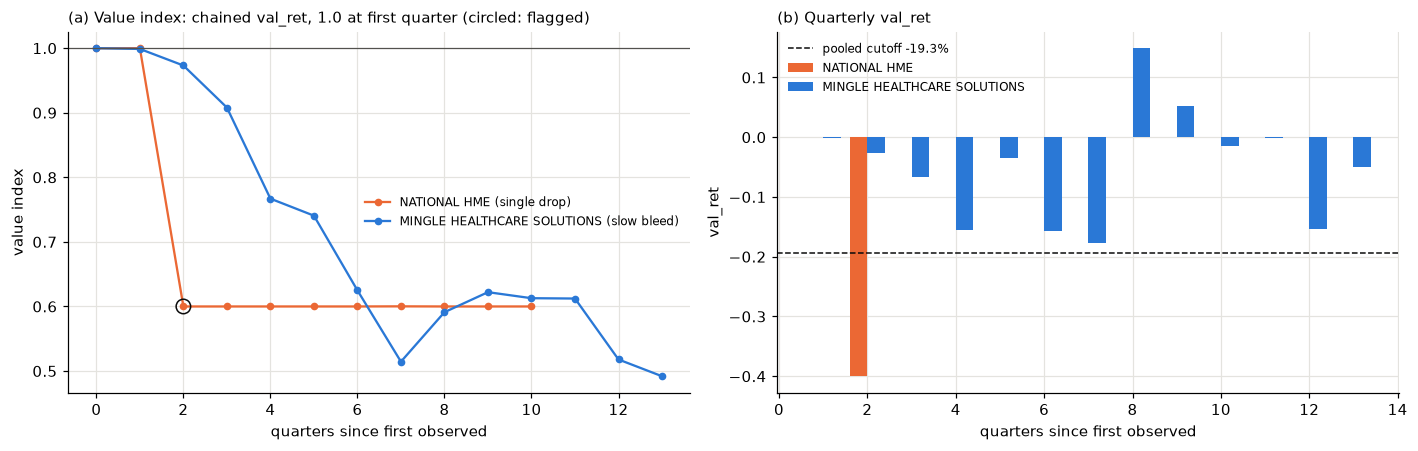

In [10]:
SINGLE, BLEED = None, None     # borrower names to override the automatic pick

# Bleed: never at or below the cutoff in a quarter, but draws down that far over its life.
bleed_pool = gradual[gradual["quarters"] >= 10]
BLEED = BLEED or (bleed_pool["max_drawdown"] + 0.5).abs().idxmin()
# Single drop: one quarter at or below the cutoff, no other quarter below -5%, similar cumulative loss.
single_pool = life[(life["worst_quarter"] <= POOLED) & (life["quarters_down_5"] == 1) & (life["quarters"] >= 10)]
SINGLE = SINGLE or (single_pool["cum_return"] - life.loc[BLEED, "cum_return"]).abs().idxmin()
print(life.loc[[SINGLE, BLEED], ["quarters", "worst_quarter", "max_drawdown", "cum_return", "quarters_down"]].round(3))

def loan_path(name):
    d = paths[paths["borrower"] == name].sort_values("qsort")
    t = (d["qsort"] - d["qsort"].iloc[0] + 1).to_numpy()
    return d, np.r_[0, t], np.r_[1.0, d["index"].to_numpy()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, color, label in [(SINGLE, ORANGE, "single drop"), (BLEED, BLUE, "slow bleed")]:
    d, t, idx = loan_path(name)
    axes[0].plot(t, idx, marker="o", ms=4, color=color, label=f"{name} ({label})")
    flagged = d["val_ret"].to_numpy() <= POOLED
    if flagged.any():
        axes[0].scatter(t[1:][flagged], idx[1:][flagged], s=90, facecolor="none", edgecolor=INK, zorder=5)
axes[0].axhline(1, color=MUTED, lw=0.8)
axes[0].set_title("(a) Value index: chained val_ret, 1.0 at first quarter (circled: flagged)", loc="left", fontsize=10)
axes[0].set_xlabel("quarters since first observed"); axes[0].set_ylabel("value index"); axes[0].legend(fontsize=8, frameon=False)

w = 0.4
for k, (name, color) in enumerate([(SINGLE, ORANGE), (BLEED, BLUE)]):
    d, t, _ = loan_path(name)
    axes[1].bar(t[1:] + (k - 0.5) * w, d["val_ret"], width=w, color=color, label=name)
axes[1].axhline(POOLED, color=INK, ls="--", lw=1, label=f"pooled cutoff {POOLED:.1%}")
axes[1].set_title("(b) Quarterly val_ret", loc="left", fontsize=10)
axes[1].set_xlabel("quarters since first observed"); axes[1].set_ylabel("val_ret"); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout()

### A measure over the whole life of the loan

Chaining `val_ret` (panel a) compounds quarterly returns. A dollar version is simpler and stays close to the definition of `val_ret`. For each borrower, over the quarters it has a return and at least $1M of prior FV:

```
life_val_ret = sum_t (FV_t - FV_t-1 - (Cost_t - Cost_t-1))  /  (FV_first + sum_t new_money_t)
```

The numerator is the total change in FV net of cost over the life, which is the lifetime change in unrealized gain/loss, so draws, paydowns and PIK still cancel. The denominator is the capital deployed: the FV at the start plus every later dollar of new money. It uses `val_ret × capital_at_risk` for each quarter's numerator and `capital_at_risk - fv_prev` for new money. A gap in coverage drops the change across the missing quarter.

                             quarters  life_val_ret  cum_return  worst_quarter
borrower                                                                      
NATIONAL HME                       10        -0.400      -0.400         -0.400
MINGLE HEALTHCARE SOLUTIONS        13        -0.499      -0.508         -0.177
life_val_ret across 12,078 borrowers: median 0.00%, 1st percentile -61.6%
life flag            False  True 
single-quarter flag              
False                11326    201
True                   142    409


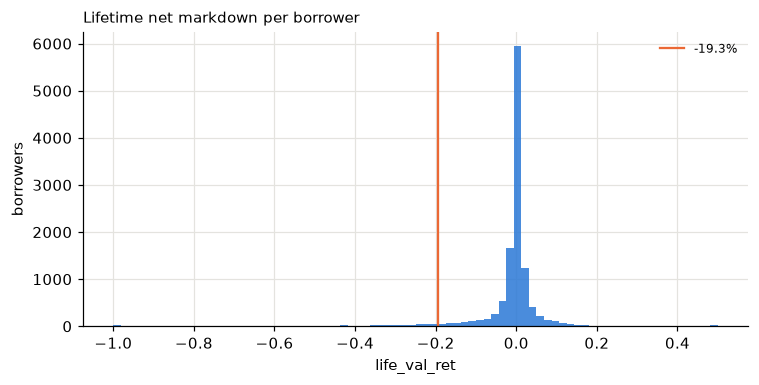

In [11]:
def life_val_ret(b_all: pd.DataFrame) -> pd.DataFrame:
    d = b_all[b_all["val_ret"].notna() & (b_all["fv_prev"] >= MIN_FV)].sort_values(["borrower", "qsort"]).copy()
    d["net_change"] = d["val_ret"] * d["capital_at_risk"]          # FV change net of cost change
    d["new_money"] = d["capital_at_risk"] - d["fv_prev"]
    g = d.groupby("borrower")
    out = g.agg(first_fv=("fv_prev", "first"), net_change=("net_change", "sum"), new_money=("new_money", "sum"),
                quarters=("val_ret", "size"))
    out["life_val_ret"] = out["net_change"] / (out["first_fv"] + out["new_money"])
    return out

lv = life_val_ret(b).join(life[["worst_quarter", "max_drawdown", "cum_return"]])
print(lv.loc[[SINGLE, BLEED], ["quarters", "life_val_ret", "cum_return", "worst_quarter"]].round(3))
print(f"life_val_ret across {len(lv):,} borrowers: median {lv['life_val_ret'].median():.2%}, "
      f"1st percentile {lv['life_val_ret'].quantile(0.01):.1%}")

lv["flag_quarter"] = lv["worst_quarter"] <= POOLED          # the current single-quarter rule
lv["flag_life"] = lv["life_val_ret"] <= POOLED              # same -19.3% loss, over the whole life
print(pd.crosstab(lv["flag_quarter"], lv["flag_life"], rownames=["single-quarter flag"], colnames=["life flag"]))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(lv["life_val_ret"].clip(-1, 0.5), bins=80, color=BLUE, alpha=0.85)
ax.axvline(POOLED, color=ORANGE, lw=1.5, label=f"{POOLED:.1%}")
ax.set_xlabel("life_val_ret"); ax.set_ylabel("borrowers"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Lifetime net markdown per borrower", loc="left", fontsize=10)
plt.tight_layout()

## 5. Will the -19% threshold hold out of sample?

The cutoff is the 1st percentile of every eligible borrower-quarter we observe. That is only as good as the sample behind it. Questions to test:

1. **How much volatility have marks shown?** The sample is short, so the cutoff may reflect a calm stretch.
2. **How stable is the cutoff inside the sample?** Does it move with the quarter, the half of the sample, or the borrowers drawn?
3. **Is the cutoff the same for every kind of loan?** Sector, size and lender count could each shift the tail.
4. **Are the marks themselves reliable?** Stale or slow marks understate how fast value falls, and borrowers who exit may be the worst cases.

### 5a. Volatility of fair value in the sample

In [12]:
ee = e.assign(_num=e["val_ret"] * e["capital_at_risk"])
book = ee.groupby("cal_q").agg(num=("_num", "sum"), cap=("capital_at_risk", "sum"))
book["book_return"] = book["num"] / book["cap"]                     # capital-weighted return of the whole book
mad_sigma = lambda s: 1.4826 * (s - s.median()).abs().median()      # robust sigma, ignores the tails
cs = e.groupby("cal_q")["val_ret"].agg(std="std", mad_sigma=mad_sigma, skew="skew", kurt=lambda s: s.kurt())

n_q = len(book)
print(f"Sample: {n_q} quarters, {e['cal_q'].min()} to {e['cal_q'].max()}")
print(f"Whole-book quarterly return: mean {book['book_return'].mean():.2%}, std {book['book_return'].std():.2%} "
      f"(annualized {book['book_return'].std() * 2:.2%}), worst {book['book_return'].min():.2%} in {book['book_return'].idxmin()}")
pooled_sd, pooled_mad = e["val_ret"].std(), mad_sigma(e["val_ret"])
print(f"Borrower-level returns, all quarters pooled: std {pooled_sd:.2%}, robust sigma {pooled_mad:.2%}, "
      f"excess kurtosis {e['val_ret'].kurt():.0f}")
print(f"The {POOLED:.1%} cutoff is {POOLED / pooled_sd:.1f} std or {POOLED / pooled_mad:.0f} robust sigmas below zero: "
      f"the tail is very fat, so a normal model would not describe it.")
within = e.groupby("borrower")["val_ret"].agg(["size", "std"])
print(f"Within a borrower over time: median std {within.loc[within['size'] >= 6, 'std'].median():.2%} "
      f"(borrowers with 6+ quarters)")
pd.concat([book["book_return"], cs], axis=1).round(4)

Sample: 13 quarters, 2023Q2 to 2026Q2
Whole-book quarterly return: mean -0.19%, std 0.39% (annualized 0.77%), worst -1.21% in 2026Q1
Borrower-level returns, all quarters pooled: std 7.59%, robust sigma 0.54%, excess kurtosis 1003
The -19.3% cutoff is -2.5 std or -36 robust sigmas below zero: the tail is very fat, so a normal model would not describe it.
Within a borrower over time: median std 0.88% (borrowers with 6+ quarters)


,book_return,std,mad_sigma,skew,kurt
cal_q,,,,,
2023Q2,-0.0001,0.0812,0.0071,15.7287,542.5089
2023Q3,0.0015,0.0555,0.0085,-5.6857,102.5862
2023Q4,0.0034,0.0868,0.0060,33.8248,1912.3345
2024Q1,0.0001,0.0593,0.0063,3.8754,278.4092
2024Q2,-0.0023,0.0934,0.0051,25.7719,1218.1987
2024Q3,-0.0007,0.0621,0.0046,2.5414,173.3943
2024Q4,-0.0044,0.0762,0.0054,16.2478,650.2781
2025Q1,-0.0020,0.0668,0.0052,9.2039,412.0093
2025Q2,0.0016,0.0775,0.0049,16.9585,600.2967


### 5b. How stable is the cutoff inside the sample?

Cutoff, first 6 quarters (2023Q2-2024Q3): -18.1%; last 7 (2024Q4-2026Q2): -19.9%
Leave-one-quarter-out cutoff ranges from -19.5% to -18.2% (pooled -19.3%)


Borrower bootstrap 95% interval for the 1% cutoff: -20.2% to -18.2%


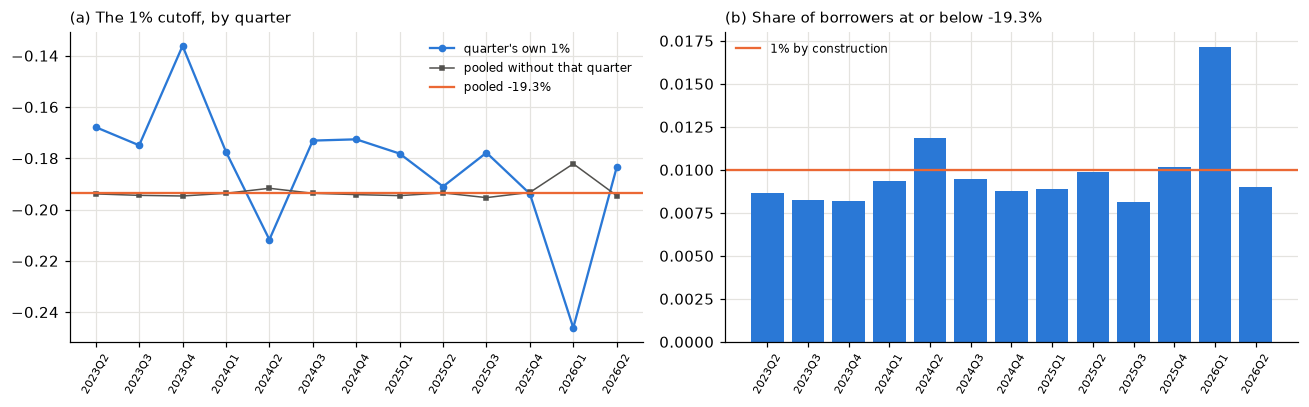

In [13]:
qs = sorted(e["cal_q"].unique())
own = e.groupby("cal_q")["val_ret"].quantile(0.01)                              # each quarter's own 1%
loo = pd.Series({k: e.loc[e["cal_q"] != k, "val_ret"].quantile(0.01) for k in qs})   # pooled without quarter k
share_below = e.assign(below=e["val_ret"] <= POOLED).groupby("cal_q")["below"].mean()
half = len(qs) // 2
cut_a = e[e["cal_q"].isin(qs[:half])]["val_ret"].quantile(0.01)
cut_b = e[e["cal_q"].isin(qs[half:])]["val_ret"].quantile(0.01)
print(f"Cutoff, first {half} quarters ({qs[0]}-{qs[half-1]}): {cut_a:.1%}; last {len(qs)-half} ({qs[half]}-{qs[-1]}): {cut_b:.1%}")
print(f"Leave-one-quarter-out cutoff ranges from {loo.min():.1%} to {loo.max():.1%} (pooled {POOLED:.1%})")

rng = np.random.default_rng(0)                                                  # resample whole borrowers
groups = [g.to_numpy() for _, g in e.groupby("borrower")["val_ret"]]
boots = [np.quantile(np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]), 0.01)
         for _ in range(200)]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Borrower bootstrap 95% interval for the 1% cutoff: {lo:.1%} to {hi:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(qs))
axes[0].plot(x, own.values, marker="o", ms=4, color=BLUE, label="quarter's own 1%")
axes[0].plot(x, loo.values, marker="s", ms=3, color=MUTED, lw=1, label="pooled without that quarter")
axes[0].axhline(POOLED, color=ORANGE, lw=1.5, label=f"pooled {POOLED:.1%}")
axes[0].set_title("(a) The 1% cutoff, by quarter", loc="left", fontsize=10)
axes[1].bar(x, share_below.values, color=BLUE)
axes[1].axhline(0.01, color=ORANGE, lw=1.5, label="1% by construction")
axes[1].set_title(f"(b) Share of borrowers at or below {POOLED:.1%}", loc="left", fontsize=10)
for ax in axes:
    ax.set_xticks(x, qs, rotation=60, fontsize=7); ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

### 5c. Is the tail the same for every kind of loan?

In [14]:
def tail_table(by):
    g = e.groupby(by, observed=True)["val_ret"]
    return pd.DataFrame({"n": g.size(), "own_1pct": g.quantile(0.01),
                         "share_at_or_below_pooled": g.apply(lambda s: (s <= POOLED).mean())})

e = e.assign(size_quartile=pd.qcut(e["fv_prev"], 4, labels=["1 smallest", "2", "3", "4 largest"]))
sec = tail_table("sector")
print("By size of prior fair value"); display(tail_table("size_quartile").round(3))
print("Held by one lender family vs several"); display(tail_table("multi_family").round(3))
print("By sector (sectors with 1,000+ borrower-quarters)"); display(sec[sec["n"] >= 1000].sort_values("own_1pct").round(3))

By size of prior fair value


,n,own_1pct,share_at_or_below_pooled
size_quartile,,,
1 smallest,20282,-0.280,0.018
2,20280,-0.218,0.012
3,20280,-0.151,0.006
4 largest,20281,-0.109,0.004


Held by one lender family vs several


,n,own_1pct,share_at_or_below_pooled
multi_family,,,
False,60070,-0.221,0.012
True,21053,-0.128,0.005


By sector (sectors with 1,000+ borrower-quarters)


,n,own_1pct,share_at_or_below_pooled
sector,,,
Consumer,11711,-0.250,0.015
Communication & Media,3359,-0.245,0.015
Materials,3391,-0.218,0.012
Real Estate,1018,-0.201,0.011
Other / Unclassified,8898,-0.199,0.010
Healthcare,11555,-0.178,0.009
Technology,12583,-0.174,0.009
Financials & Insurance,9841,-0.172,0.008
Industrials,16516,-0.165,0.008


### 5d. Can the marks be trusted?

In [15]:
# (1) Stale marks: how often is the quarterly return exactly zero?
zero_share = (e["val_ret"].abs() < 1e-9).groupby(e["cal_q"]).mean()
print(f"Share of eligible borrower-quarters with an unchanged mark (val_ret = 0): {(e['val_ret'].abs() < 1e-9).mean():.1%}")

# (2) Slow marks: does a markdown continue next quarter? Correlation of consecutive returns.
b_sorted = b.sort_values(["borrower", "qsort"])
prev = b_sorted.groupby("borrower")["val_ret"].shift(1)
linked = (b_sorted["qsort"] - b_sorted.groupby("borrower")["qsort"].shift(1) == 1) & b_sorted["eligible"] & prev.notna()
ac = b_sorted.loc[linked, "val_ret"].corr(prev[linked])
print(f"Correlation of a borrower's return with its previous quarter's return: {ac:.2f}")
after = b_sorted.loc[linked & (prev <= POOLED), "val_ret"]
print(f"Return the quarter after a drop at or below {POOLED:.1%}: mean {after.mean():.1%}, median {after.median():.1%} (n={len(after)})")

# (3) Attrition: do the worst marks disappear from the sample the next quarter?
keys = pd.MultiIndex.from_frame(b[["borrower", "qsort"]])
nxt = pd.MultiIndex.from_arrays([e["borrower"], e["qsort"] + 1]).isin(keys)
tmp = e.assign(missing_next=~nxt)[e["qsort"] < e["qsort"].max()]
tmp["bucket"] = pd.cut(tmp["val_ret"], [-2, POOLED, -0.05, 0, 10], labels=[f"<= {POOLED:.1%}", "-19% to -5%", "-5% to 0", "above 0"])
print("\nShare of borrower-quarters with no observation the next quarter, by return")
tmp.groupby("bucket", observed=True)["missing_next"].agg(["size", "mean"]).round(3)

Share of eligible borrower-quarters with an unchanged mark (val_ret = 0): 7.6%
Correlation of a borrower's return with its previous quarter's return: 0.02
Return the quarter after a drop at or below -19.3%: mean -0.2%, median -4.9% (n=551)

Share of borrower-quarters with no observation the next quarter, by return


,size,mean
bucket,,
<= -19.3%,743,0.186
-19% to -5%,2811,0.086
-5% to 0,39678,0.061
above 0,30238,0.059


### 5e. Evidence for a continuous version of `val_ret`

The alternative to a cutoff is to use `val_ret` itself, or its rank, as a score. We test it against the one outcome the data offers: a borrower with no non-accrual at *t* going on non-accrual within the next four quarters. This is a consistency check, not ground truth. Non-accrual is only recorded for some BDCs (rows with it unobserved are dropped), and falling marks and non-accrual often arrive together.

The scores compared, all oriented so that a higher score means more distress:

| Score | What it is |
|---|---|
| `flag_pooled` | 1 if `val_ret` is at or below the pooled 1% (-19.3%), else 0 (the current rule) |
| `flag_fixed_10` | 1 if `val_ret` is at or below -10% |
| `val_ret` | minus the quarterly return, continuous |
| `excess` | minus the return net of the quarter's median, continuous |
| `cum_to_date` | minus the chained return since the borrower first appeared (the life measure of section 4, up to *t*) |

**AUC** is the chance that a random borrower-quarter that later goes non-accrual scores higher than one that does not (0.5 is chance).

In [16]:
# Outcome: no non-accrual at t, some non-accrual in t+1..t+4. Rows with no non-accrual data in t+1..t+4 are dropped.
f = e[["borrower", "qsort", "cal_q", "val_ret", "na_cost_share"]].copy()
for k in range(1, 5):
    s = b[["borrower", "qsort", "na_cost_share"]].assign(qsort=lambda d: d["qsort"] - k).rename(columns={"na_cost_share": f"na{k}"})
    f = f.merge(s, on=["borrower", "qsort"], how="left")
nx = f[[f"na{k}" for k in range(1, 5)]]
f["observed"] = nx.notna().any(axis=1)
f["y"] = ((nx.fillna(0) > 0).any(axis=1) & (f["na_cost_share"].fillna(0) == 0)).astype(float).where(f["observed"])
f = f.merge(paths[["borrower", "qsort", "index"]], on=["borrower", "qsort"], how="left")
f["excess"] = f["val_ret"] - f.groupby("cal_q")["val_ret"].transform("median")
g = f[f["observed"] & f["index"].notna()].copy()
g["flag_pooled"] = (g["val_ret"] <= POOLED).astype(float)
g["flag_fixed_10"] = (g["val_ret"] <= -0.10).astype(float)
g["val_ret_s"], g["excess_s"], g["cum_to_date"] = -g["val_ret"], -g["excess"], -(g["index"] - 1)
print(f"{len(g):,} borrower-quarters with the outcome observed; {g['y'].mean():.1%} go on non-accrual within 4 quarters")

def auc(score, y):
    r = score.rank(method="average"); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

SCORES = ["flag_pooled", "flag_fixed_10", "val_ret_s", "excess_s", "cum_to_date"]
cut_q = g["qsort"].median()
res = pd.DataFrame({
    "AUC": {s: auc(g[s], g["y"]) for s in SCORES},
    "AUC first half": {s: auc(g.loc[g["qsort"] <= cut_q, s], g.loc[g["qsort"] <= cut_q, "y"]) for s in SCORES},
    "AUC second half": {s: auc(g.loc[g["qsort"] > cut_q, s], g.loc[g["qsort"] > cut_q, "y"]) for s in SCORES},
})
res.round(3)

63,416 borrower-quarters with the outcome observed; 2.6% go on non-accrual within 4 quarters


,AUC,AUC first half,AUC second half
flag_pooled,0.521,0.523,0.518
flag_fixed_10,0.557,0.559,0.555
val_ret_s,0.682,0.694,0.677
excess_s,0.688,0.694,0.686
cum_to_date,0.745,0.738,0.765


In [17]:
# What does the cutoff throw away? Catch rate when flagging the worst x% of borrower-quarters.
base = g["y"].mean(); tot_events = g["y"].sum()
rows_ = []
for name in ["val_ret_s", "cum_to_date"]:
    for pct in (0.01, 0.02, 0.05, 0.10):
        top = g[name] >= g[name].quantile(1 - pct)
        rows_.append({"score": name, "flag worst": f"{pct:.0%}", "flagged": int(top.sum()),
                      "precision": g.loc[top, "y"].mean(), "recall": g.loc[top, "y"].sum() / tot_events,
                      "lift": g.loc[top, "y"].mean() / base})
print(f"Base rate {base:.1%}. The current rule flags the worst {g['flag_pooled'].mean():.1%} ({int(g['flag_pooled'].sum())} borrower-quarters).")
pd.DataFrame(rows_).set_index(["score", "flag worst"]).round(3)

Base rate 2.6%. The current rule flags the worst 0.9% (563 borrower-quarters).


flagged  precision  recall   lift
score       flag worst                                   
val_ret_s   1%              635      0.151   0.058  5.800
            2%             1269      0.154   0.118  5.895
            5%             3171      0.138   0.265  5.299
            10%            6342      0.104   0.399  3.986
cum_to_date 1%              635      0.123   0.047  4.712
            2%             1269      0.148   0.114  5.684
            5%             3171      0.164   0.314  6.279
            10%            6342      0.133   0.509  5.093

,size,new_non_accrual_4q
bin,,
"(-1.0, -0.4]",141,0.085
"(-0.4, -0.3]",111,0.189
"(-0.3, -0.2]",272,0.165
"(-0.2, -0.15]",304,0.148
"(-0.15, -0.1]",555,0.173
"(-0.1, -0.05]",1587,0.124
"(-0.05, -0.02]",3363,0.072
"(-0.02, 0.0]",30724,0.019
"(0.0, 0.02]",21683,0.013


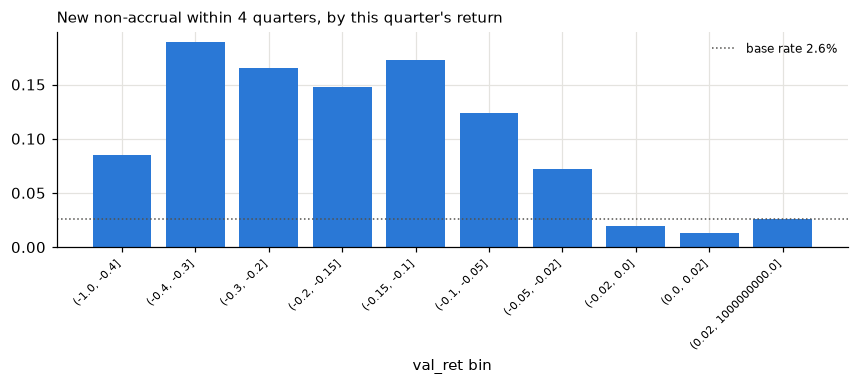

In [18]:
# Dose-response: does risk jump at the cutoff, or rise smoothly?
cuts = [-1.0, -0.40, -0.30, -0.20, -0.15, -0.10, -0.05, -0.02, 0.0, 0.02, 1e9]
g["bin"] = pd.cut(g["val_ret"], cuts)
dose = g.groupby("bin", observed=True)["y"].agg(["size", "mean"]).rename(columns={"mean": "new_non_accrual_4q"})
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(dose)), dose["new_non_accrual_4q"], color=BLUE)
ax.set_xticks(range(len(dose)), [str(i) for i in dose.index], rotation=45, ha="right", fontsize=7)
ax.axhline(base, color=MUTED, lw=1, ls=":", label=f"base rate {base:.1%}")
ax.set_title("New non-accrual within 4 quarters, by this quarter's return", loc="left", fontsize=10)
ax.set_xlabel("val_ret bin"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
dose.round(3)

**What the evidence says.** 63,416 borrower-quarters have the outcome observed, and 2.6% go on non-accrual within four quarters.

- **The risk rises well before -19%.** The new non-accrual rate is about 1–2% for returns near zero, 7% from -5% to -2%, 12% from -10% to -5%, and then it plateaus at 15–19% from -10% down to -40%. Most of the climb is between 0 and -10%. A cutoff at -19% sits on the flat part and ignores the steep part. Consistent with this, a fixed -10% flag has a higher AUC (0.557) than the pooled -19.3% flag (0.521).
- **A continuous score ranks better.** AUC is 0.68 for `val_ret`, 0.69 for the market-relative `excess`, and 0.745 for the cumulative-to-date measure, against 0.52 for the current flag. This comparison is partly mechanical, since a 0/1 flag has only two levels. The cleaner points are the next two.
- **At the same number flagged, the flag is no worse.** Flagging the worst 1% by `val_ret` is the current rule, with a precision of 15% and a recall of 6%. The gain from a continuous score is the choice of how many to flag. The worst 5% catches 26.5% of later non-accruals at a lift of 5.3, and the worst 10% by cumulative-to-date catches 51% at a lift of 5.1. The cutoff cannot do this.
- **Cumulative-to-date beats the single quarter** for catching losses that build up (recall 31% against 26.5% at 5% flagged), consistent with section 4.
- **It holds over time.** AUC is 0.694 in the first half of the sample and 0.677 in the second for `val_ret`, and 0.738 and 0.765 for cumulative-to-date. A ranking does not depend on where a cutoff falls in a given quarter, so it is less exposed to the 2026Q1 problem. The `excess` score (return net of the quarter's median) is the most stable across halves, with AUC 0.694 and 0.686.

**Caveats.**
- The relationship is not monotone at the far end: the -100% to -40% bin has a lower non-accrual rate (8.5%) than milder ones, based on only 141 borrower-quarters. Those loans may already be marked to near zero or restructured. Use the rank rather than the raw return, and winsorize the score.
- The sample of outcomes is small in the tails, and non-accrual status is only observed for some BDCs.
- This tests consistency with one outcome. It does not show that a continuous score would predict losses in a downturn.

### 5f. What this says about the -19% threshold

**Inside the sample it is stable.** The cutoff is -18.1% in the first six quarters and -19.9% in the last seven. Dropping any one quarter moves it between -18.2% and -19.5%, and a borrower-level bootstrap gives -20.2% to -18.2%. Sampling noise is not the concern.

**The concern is what the sample cannot show.**

- **Short and calm.** Thirteen quarters (2023Q2 to 2026Q2), with no full credit cycle. The whole book's quarterly return has a standard deviation of 0.39% (0.77% annualized) and its worst quarter is -1.2% (2026Q1). A broad downturn would be out of range. In 2026Q1, a mild market-wide repricing, the share of borrowers beyond the cutoff rose from about 0.9% to 1.7%, and that quarter's own 1% was -24.6%. A fixed cutoff flags many more loans when marks fall together, so "1% of loans" would stop being the definition.
- **A fat tail.** Borrower returns have a standard deviation of 7.6%, but the typical (robust) spread is 0.5%, with excess kurtosis near 1,000. The cutoff sits 36 robust sigmas from zero. It is set by a few hundred extreme marks, so it can move a lot if the next few years produce a different mix of extremes.
- **Different loans, different tails.** The cutoff is not uniform. The smallest quartile of positions has its own 1% at -28% and the largest at -11%, so the pooled cutoff flags 1.8% of the smallest and 0.4% of the largest. Loans held by one lender family have a 1% of -22%, against -13% for loans held by several. Sectors range from -25% (Consumer) to -14% (Energy & Utilities). If the mix of loans shifts toward small or single-lender positions, the share flagged will rise without any change in credit quality.
- **Marks may be slow.** 7.6% of borrower-quarters have an unchanged mark. The correlation of a return with the previous quarter's is only 0.02, but the quarter after a flagged drop the median return is a further -4.9%. So marks keep falling after the cutoff is crossed, and a one-quarter threshold may catch the start of a decline rather than the whole of it.
- **The worst loans leave the sample.** 18.6% of borrower-quarters at or below the cutoff have no observation the next quarter, against about 6% for everyone else. That could be a restructuring, a sale, or a loan that dropped out of the data. Losses on these loans are not tracked afterward.

**Practical implications.**
- The cutoff is best treated as a definition for this sample, not as a threshold with a fixed meaning. The continuous score in 5e gives a ranking that needs no cutoff, and it separates later non-accruals better than the flag.
- A cutoff expressed as a rank or by loan type (size, single-lender, sector) would be less sensitive to the mix of loans.
- The market-relative version in section 3 (return minus the quarter median) handles 2026Q1-style repricings.
- The lifetime measure in section 4 catches losses that arrive in small steps.
- A downturn cannot be tested with this data. A longer history, or the CDLI benchmark, would be the way to check how the tail behaves then.

## 6. Price instead of fair value

`val_ret` works on dollars of fair value and nets out cost to remove money flows. The alternative is to work on **price** (FV ÷ par), which is already per dollar of principal. This section asks three questions: where can we price, what is a price-based return net of money flows, and how does its distribution over a borrower's life compare with `val_ret`.

**The measure.** For each loan (tranche) that is priced in two consecutive quarters, take the change in price and apply it to *last quarter's par*, so draws, paydowns and PIK (which change par) are held out:

```
price_ret = sum over loans of  PAR_t-1 * (price_t - price_t-1)  /  sum over loans of  FV_t-1
```

This is the price analog of netting out cost: the dollar change in value if the principal had stayed where it was, as a share of last quarter's fair value. All sums use only the priced rows (`FV_px`, `PAR_px`) and are added across loans and lenders for each borrower, then compared with the same `MIN_FV_PREV` floor as `val_ret`. Prices above 150% of par are dropped as currency errors.

### 6a. Where can we price?

In [19]:
priced = panel["PAR_px"] > 0
print(f"Loan-quarters (one per BDC x loan x quarter): {len(panel):,}; with a price: {priced.mean():.1%}")
print(f"Share of fair value on priced rows: {panel['FV_px'].sum() / panel['FV'].sum():.1%}; "
      f"share of par: {panel['PAR_px'].sum() / panel['PAR'].sum():.1%}")
over = priced & (panel["FV_px"] / panel["PAR_px"] > D.MAX_PRICE)
print(f"Priced above {D.MAX_PRICE:.0%} of par (dropped as data errors): {over.sum():,} loan-quarters")

unp = panel[~priced]
why = pd.cut(unp["COST"] / unp["PAR"], [-np.inf, 0.05, 0.8, np.inf],
             labels=["cost under 5% of par (unfunded)", "cost 5% to 80% of par", "cost at least 80% of par"])
print(f"\nWhy the {len(unp):,} unpriced loan-quarters are unpriced (cost as a share of par), and the fair value they hold:")
pd.DataFrame({"loan_quarters": why.value_counts(), "fair_value_$m": unp.groupby(why, observed=True)["FV"].sum() / 1e6}).round(1)

Loan-quarters (one per BDC x loan x quarter): 282,749; with a price: 97.8%
Share of fair value on priced rows: 99.1%; share of par: 98.0%
Priced above 150% of par (dropped as data errors): 416 loan-quarters

Why the 6,260 unpriced loan-quarters are unpriced (cost as a share of par), and the fair value they hold:


,loan_quarters,fair_value_$m
cost under 5% of par (unfunded),2,0.1
cost 5% to 80% of par,6258,25855.0
cost at least 80% of par,0,NaN


In [20]:
pt = panel[priced & ~panel["borrower_key"].str.startswith("ID: ")].copy()
pt["price_t"] = pt["FV_px"] / pt["PAR_px"]
pt = pt[pt["price_t"] <= D.MAX_PRICE].sort_values(["chain_id", "qsort"])
gp = pt.groupby("chain_id")
linked = (pt["qsort"] - gp["qsort"].shift(1) == 1) & (gp["FV_px"].shift(1) > 0)
pt["_num"] = (gp["PAR_px"].shift(1) * (pt["price_t"] - gp["price_t"].shift(1))).where(linked)
pt["_den"] = gp["FV_px"].shift(1).where(linked)
pt["borrower"] = pt["borrower_key"].str.strip().str.upper()
pb = pt.groupby(["borrower", "cal_q"]).agg(_num=("_num", "sum"), _den=("_den", "sum")).reset_index()
pb["price_ret"] = (pb["_num"] / pb["_den"]).where(pb["_den"] > 0)
pb = pb.rename(columns={"_den": "px_fv_prev"}).drop(columns="_num")

bp = b.merge(pb, on=["borrower", "cal_q"], how="left")
bp["val_ok"] = bp["eligible"]
bp["price_ok"] = bp["price_ret"].notna() & (bp["px_fv_prev"] >= MIN_FV)
bp["price_ret_w"] = bp["price_ret"].clip(-1, 1)

cov = bp.groupby("cal_q").agg(borrower_quarters=("borrower", "size"), val_ret=("val_ok", "sum"), price_ret=("price_ok", "sum"),
                              both=("val_ok", lambda s: (s & bp.loc[s.index, "price_ok"]).sum()))
cov.loc["total"] = cov.sum()
cov["price_share_of_val"] = cov["both"] / cov["val_ret"]
print("Borrower-quarters where each return can be computed (val_ret: eligible rows; price_ret: priced in both quarters, same $1M floor)")
cov

Borrower-quarters where each return can be computed (val_ret: eligible rows; price_ret: priced in both quarters, same $1M floor)


,borrower_quarters,val_ret,price_ret,both,price_share_of_val
cal_q,,,,,
2023Q1,5023,0,0,0,NaN
2023Q2,5399,4393,4318,4318,0.982927
2023Q3,5977,4716,4651,4651,0.986217
2023Q4,6205,4995,4932,4932,0.987387
2024Q1,6644,5445,5332,5332,0.979247
2024Q2,7014,5741,5631,5631,0.980840
2024Q3,7428,6016,5927,5927,0.985206
2024Q4,7631,6149,6061,6061,0.985689
2025Q1,7881,6650,6544,6544,0.984060


In [21]:
both_ = bp[bp["val_ok"] & bp["price_ok"]]
only_val = bp[bp["val_ok"] & ~bp["price_ok"]]
print(f"val_ret eligible: {bp['val_ok'].sum():,}; price_ret eligible: {bp['price_ok'].sum():,}; both: {len(both_):,}")
print(f"Fair value in val_ret rows with no price_ret: {only_val['fv_prev'].sum() / bp.loc[bp['val_ok'], 'fv_prev'].sum():.1%} "
      f"of prior fair value ({len(only_val):,} borrower-quarters)")
print(f"Correlation of val_ret and price_ret on the {len(both_):,} common rows: "
      f"{both_['val_ret'].corr(both_['price_ret']):.3f} (rank correlation {both_['val_ret'].rank().corr(both_['price_ret'].rank()):.3f})")

val_ret eligible: 81,123; price_ret eligible: 79,840; both: 79,840
Fair value in val_ret rows with no price_ret: 0.3% of prior fair value (1,283 borrower-quarters)
Correlation of val_ret and price_ret on the 79,840 common rows: 0.855 (rank correlation 0.812)


### 6b. Compounded price return over the life of a borrower

In [22]:
def chain(d, col):
    d = d[d[col].notna()].sort_values(["borrower", "qsort"]).copy()
    seg = ((d["borrower"] != d["borrower"].shift()) | (d["qsort"].diff() != 1)).cumsum()
    d["seg"] = seg
    d["index"] = d.groupby("seg")[col].transform(lambda s: (1 + s).cumprod())
    d["drawdown"] = d["index"] / d.groupby("seg")["index"].cummax().clip(lower=1.0) - 1
    return d

pp = chain(bp[bp["price_ok"]], "price_ret_w")
plife = pp.groupby("borrower").agg(quarters=("price_ret", "size"), worst_quarter=("price_ret", "min"),
                                   max_drawdown=("drawdown", "min"), cum_return=("index", "last"))
plife["cum_return"] -= 1
both_life = plife.join(life[["worst_quarter", "max_drawdown", "cum_return"]], rsuffix="_val", how="inner")
print(f"{len(plife):,} borrowers with a price return; {len(both_life):,} also have a val_ret life")
plife.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95]).round(3)

11,911 borrowers with a price return; 11,911 also have a val_ret life


,quarters,worst_quarter,max_drawdown,cum_return
count,11911.000,11911.000,11911.000,11911.000
mean,6.703,-0.035,-0.050,-0.018
std,4.118,0.094,0.125,0.125
min,1.000,-0.977,-0.995,-0.995
1%,1.000,-0.510,-0.701,-0.668
5%,1.000,-0.183,-0.270,-0.205
25%,3.000,-0.025,-0.032,-0.008
50%,6.000,-0.007,-0.008,0.002
75%,11.000,-0.000,-0.000,0.015
95%,13.000,0.005,0.000,0.064


On the common rows, borrower-quarters flagged at each measure's own 1%: val_ret 735, price_ret 799, in both 669 (Jaccard 0.77)


,worst_quarter_val,worst_quarter,max_drawdown_val,max_drawdown,cum_return_val,cum_return
count,11911.000,11911.000,11911.000,11911.000,11911.000,11911.000
mean,-0.035,-0.035,-0.051,-0.050,-0.020,-0.018
std,0.091,0.094,0.121,0.125,0.128,0.125
min,-0.969,-0.977,-0.989,-0.995,-0.989,-0.995
1%,-0.513,-0.510,-0.688,-0.701,-0.631,-0.668
5%,-0.170,-0.183,-0.270,-0.270,-0.190,-0.205
25%,-0.026,-0.025,-0.035,-0.032,-0.011,-0.008
50%,-0.008,-0.007,-0.011,-0.008,0.000,0.002
75%,-0.001,-0.000,-0.002,-0.000,0.010,0.015
max,0.425,0.398,0.000,0.000,4.324,1.458


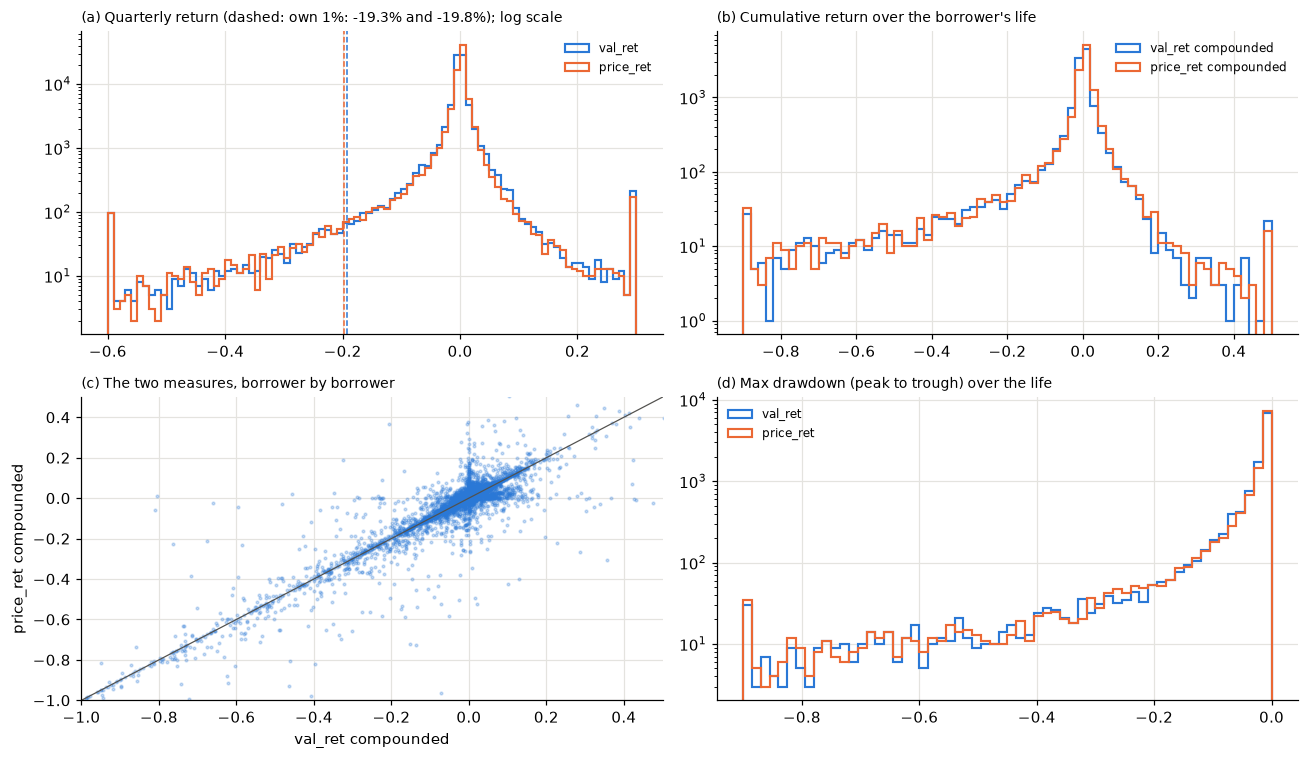

In [23]:
POOLED_PX = bp.loc[bp["price_ok"], "price_ret"].quantile(0.01)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
bins = np.linspace(-0.6, 0.3, 91)
ax = axes[0, 0]
ax.hist(bp.loc[bp["val_ok"], "val_ret"].clip(-0.6, 0.3), bins=bins, histtype="step", color=BLUE, lw=1.4, label="val_ret")
ax.hist(bp.loc[bp["price_ok"], "price_ret"].clip(-0.6, 0.3), bins=bins, histtype="step", color=ORANGE, lw=1.4, label="price_ret")
ax.axvline(POOLED, color=BLUE, ls="--", lw=1); ax.axvline(POOLED_PX, color=ORANGE, ls="--", lw=1)
ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8)
ax.set_title(f"(a) Quarterly return (dashed: own 1%: {POOLED:.1%} and {POOLED_PX:.1%}); log scale", loc="left", fontsize=9)

ax = axes[0, 1]
cb = np.linspace(-0.9, 0.5, 71)
ax.hist(both_life["cum_return_val"].clip(-0.9, 0.5), bins=cb, histtype="step", color=BLUE, lw=1.4, label="val_ret compounded")
ax.hist(both_life["cum_return"].clip(-0.9, 0.5), bins=cb, histtype="step", color=ORANGE, lw=1.4, label="price_ret compounded")
ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8)
ax.set_title("(b) Cumulative return over the borrower's life", loc="left", fontsize=9)

ax = axes[1, 0]
ax.scatter(both_life["cum_return_val"], both_life["cum_return"], s=3, alpha=0.25, color=BLUE)
ax.plot([-1, 0.5], [-1, 0.5], color=MUTED, lw=0.8)
ax.set_xlim(-1, 0.5); ax.set_ylim(-1, 0.5)
ax.set_xlabel("val_ret compounded"); ax.set_ylabel("price_ret compounded")
ax.set_title("(c) The two measures, borrower by borrower", loc="left", fontsize=9)

ax = axes[1, 1]
ax.hist(both_life["max_drawdown_val"].clip(-0.9, 0), bins=60, histtype="step", color=BLUE, lw=1.4, label="val_ret")
ax.hist(both_life["max_drawdown"].clip(-0.9, 0), bins=60, histtype="step", color=ORANGE, lw=1.4, label="price_ret")
ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8)
ax.set_title("(d) Max drawdown (peak to trough) over the life", loc="left", fontsize=9)
plt.tight_layout()

fl_v = set(bp.loc[bp["val_ok"] & bp["price_ok"] & (bp["val_ret"] <= POOLED), ["borrower", "cal_q"]].itertuples(index=False, name=None))
fl_p = set(bp.loc[bp["val_ok"] & bp["price_ok"] & (bp["price_ret"] <= POOLED_PX), ["borrower", "cal_q"]].itertuples(index=False, name=None))
print(f"On the common rows, borrower-quarters flagged at each measure's own 1%: val_ret {len(fl_v)}, price_ret {len(fl_p)}, "
      f"in both {len(fl_v & fl_p)} (Jaccard {len(fl_v & fl_p) / len(fl_v | fl_p):.2f})")
both_life[["worst_quarter_val", "worst_quarter", "max_drawdown_val", "max_drawdown", "cum_return_val", "cum_return"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75]).round(3)